In [ ]:
!pip install datasets torch -q

import torch
import torch.nn as nn
from torch.nn import functional as F
from datasets import load_dataset
import matplotlib.pyplot as plt
import math

# Check if the GPU is working
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [ ]:
print("Downloading TinyStories dataset...")
dataset = load_dataset("roneneldan/TinyStories")

# To make training fast, we will only use the first 5,000 stories.
# (If you use the whole dataset, it will take hours!)
stories = dataset['train']['text'][:5000]

print(f"Loaded {len(stories)} stories.")
print("\nHere is an example story:\n")
print(stories[0])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Loaded 5000 stories.

Here is an example story:

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.


In [ ]:
# Get all unique characters in the text
chars = sorted(list(set(''.join(stories))))
vocab_size = len(chars)
print(f"There are {vocab_size} unique characters in the dataset.")

# Create a dictionary to convert letters to numbers and vice versa
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

# Helper functions to encode (text to numbers) and decode (numbers to text)
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

print("Text: 'Once upon a time'")
print("Numbers:", encode("Once upon a time"))

There are 90 unique characters in the dataset.
Text: 'Once upon a time'
Numbers: [36, 61, 50, 52, 1, 68, 63, 62, 61, 1, 48, 1, 67, 56, 60, 52]


In [ ]:
# Let's turn the stories into a big chunk of numbers
data = torch.tensor(encode(''.join(stories)), dtype=torch.long)

# We split it: 90% for training the AI, 10% for testing it
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

# Settings
block_size = 128 # How many characters the AI looks at to predict the next one
batch_size = 32  # How many chunks it processes at once

def get_batch(split):
    data_source = train_data if split == 'train' else val_data
    ix = torch.randint(len(data_source) - block_size, (batch_size,))
    x = torch.stack([data_source[i:i+block_size] for i in ix])
    y = torch.stack([data_source[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

print("Data prepared!")

Data prepared!


In [ ]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, n_embd, n_head, n_layer):
        super().__init__()
        # 1. Embeddings (Turning numbers into meaning)
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)

        # 2. The Transformer Blocks (Attention + Feed Forward)
        self.blocks = nn.Sequential(*[
            nn.TransformerEncoderLayer(d_model=n_embd, nhead=n_head, batch_first=True)
            for _ in range(n_layer)
        ])

        # 3. Output layer (Predicting the next letter)
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb

        # Masking so the AI doesn't look into the future!
        mask = nn.Transformer.generate_square_subsequent_mask(T).to(idx.device)

        # Pass through the Transformer layers
        x = self.blocks[0](x, src_mask=mask)

        logits = self.lm_head(self.ln_f(x))

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

# Create the model
model = TinyTransformer(vocab_size=vocab_size, n_embd=64, n_head=4, n_layer=2).to(device)
print(f"Model created with {sum(p.numel() for p in model.parameters())} parameters.")

Model created with 582234 parameters.


Starting training... (This will take about 1-2 minutes)
Step 0: Loss = 4.6613
Step 200: Loss = 2.3864
Step 400: Loss = 2.2524
Step 600: Loss = 2.0578
Step 800: Loss = 1.9571


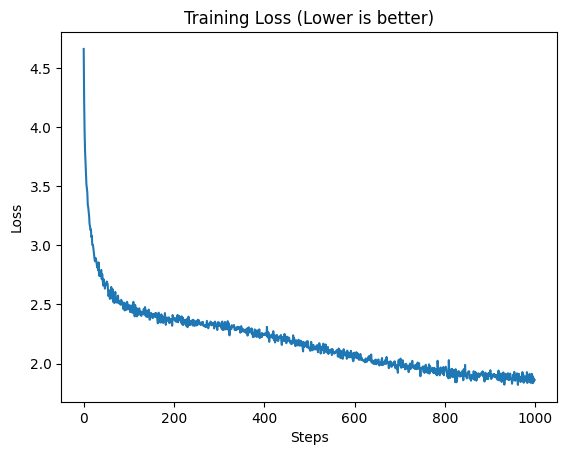

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
losses = []

print("Starting training... (This will take about 1-2 minutes)")
for step in range(1000):
    # Get a batch of data
    xb, yb = get_batch('train')

    # Predict and calculate error
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)

    # Update the model's brain
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if step % 200 == 0:
        print(f"Step {step}: Loss = {loss.item():.4f}")

# Draw a graph of the training progress
plt.plot(losses)
plt.title("Training Loss (Lower is better)")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.show()

In [ ]:
# Put model in evaluation mode
model.eval()

def generate(prompt, max_new_tokens=200):
    # Encode the prompt
    context = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)

    for _ in range(max_new_tokens):
        # Only look at the last 'block_size' characters
        context_crop = context[:, -block_size:]

        # Get predictions
        with torch.no_grad():
            logits, _ = model(context_crop)

        # Focus only on the last time step
        logits = logits[:, -1, :]

        # Apply softmax to get probabilities
        probs = F.softmax(logits, dim=-1)

        # Sample from the distribution
        next_id = torch.multinomial(probs, num_samples=1)

        # Append to context
        context = torch.cat((context, next_id), dim=1)

    return decode(context[0].tolist())

print("--- GENERATING STORY ---")
story = generate("Once upon a time")
print(story)
print("------------------------")

--- GENERATING STORY ---
Once upon a timed here was hat to peved and but un, the selfing to want wat ch and qu so lay, of he was wy, so ras sa was hin way loomew the gaves. Ap. She maree had usawas sknd braddy, crom bound was wing bed aged w
------------------------


In [ ]:
# Save the brain to a file
torch.save(model.state_dict(), 'tiny_transformer_model.pth')
print("Model saved successfully!")

Model saved successfully!
